# Visium - SCA013

## Import packages

In [2]:
%load_ext autoreload
%autoreload 2

In [ ]:
import harpy as hp
import spatialdata as sd
import pandas as pd
import numpy as np
import dask as da
import os
import gc
import geopandas as gpd
from matplotlib import pyplot as plt
import seaborn as sns
import h5py
import json
import gc

from dask_image.imread import imread
import spatialdata_plot

c:\Users\julien.mortier\conda-envs\harpy\lib\site-packages\xarray_schema\__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


In [1]:
from _visium import visium

c:\Users\julien.mortier\conda-envs\harpy\lib\site-packages\dask\dataframe\__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
c:\Users\julien.mortier\conda-envs\harpy\lib\site-packages\xarray_schema\__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
c:\Users\julien.mortier\conda-envs\harpy\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


## Create sdata

In [3]:
path_outs = r'D:\2024-07-UTBenchmark-SpC\data\raw\Visium\SCA013\COUNTS\SCA013\SCA013_reseq\outs'
path_img = r'D:\2024-07-UTBenchmark-SpC\data\raw\Visium\SCA013\IMAGES\SCA013_HE_hires.tif'
counts_file = "raw_feature_bc_matrix.h5"
dataset_id = 'SCA013'
output_path = r'D:\2024-07-UTBenchmark-SpC\data\processed\Visium\SCA013\harpy\sdata.zarr'

In [4]:
# Create SpatialData from Space Ranger output
sdata = visium(
    path = path_outs, 
    counts_file = counts_file,
    dataset_id = dataset_id,
    fullres_image_file = path_img,
    output = output_path
)

sdata

INFO     reading                                                                                                   
         D:\2024-07-UTBenchmark-SpC\data\raw\Visium\SCA013\COUNTS\SCA013\SCA013_reseq\outs\raw_feature_bc_matrix.h5


c:\Users\julien.mortier\conda-envs\harpy\lib\site-packages\anndata\_core\anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
c:\Users\julien.mortier\conda-envs\harpy\lib\site-packages\anndata\_core\anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
c:\Users\julien.mortier\conda-envs\harpy\lib\site-packages\spatialdata\models\models.py:1144: UserWarning: Converting `region_key: region` to categorical dtype.
  return convert_region_column_to_categorical(adata)
<tifffile.TiffFile 'SCA013_HE_hires.tif'> ImageJ series metadata invalid or corrupted file
c:\Users\julien.mortier\conda-envs\harpy\lib\site-packages\spatialdata\_core\_elements.py:105: UserWarning: Key `SCA013` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
2025-08-07 12:08:21,601 - harpy

INFO     The Zarr backing store has been changed from None the new file path:                                      
         D:\2024-07-UTBenchmark-SpC\data\processed\Visium\SCA013\harpy\sdata.zarr                                  


version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


SpatialData object, with associated Zarr store: D:\2024-07-UTBenchmark-SpC\data\processed\Visium\SCA013\harpy\sdata.zarr
├── Images
│     ├── 'SCA013_full_image': DataTree[cyx] (3, 11995, 14569), (3, 5997, 7284), (3, 2998, 3642), (3, 1499, 1821), (3, 749, 910)
│     ├── 'SCA013_hires_image': DataArray[cyx] (3, 1647, 2000)
│     └── 'SCA013_lowres_image': DataArray[cyx] (3, 494, 600)
├── Labels
│     └── 'SCA013_labels': DataArray[yx] (13860, 14162)
├── Shapes
│     └── 'SCA013': GeoDataFrame shape: (4970, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (4970, 32285)
with coordinate systems:
    ▸ 'SCA013', with elements:
        SCA013_full_image (Images), SCA013_hires_image (Images), SCA013_lowres_image (Images)
    ▸ 'SCA013_downscaled_hires', with elements:
        SCA013_hires_image (Images)
    ▸ 'SCA013_downscaled_lowres', with elements:
        SCA013_lowres_image (Images)
    ▸ 'global', with elements:
        SCA013_labels (Labels), SCA013 (Shapes)

ValueError: The SpatialData object does not contain any element in the coordinate system 'global', please pass a different coordinate system with the argument 'coordinate_system'.

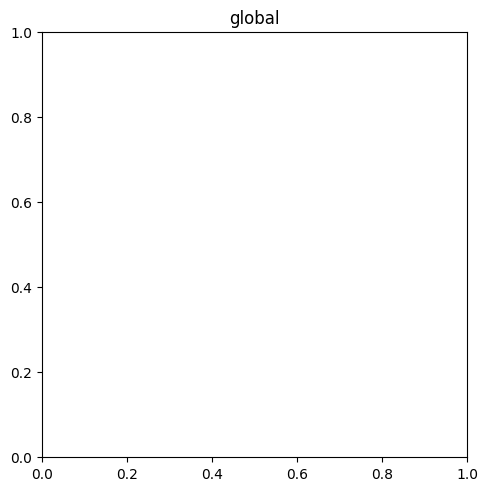

In [ ]:
# Check spots
sdata.pl.render_images(
    element="SCA013_full_image"
# ).pl.render_labels(
    # element="SCA013_labels", fill_alpha=0.1, contour_px=5, outline_alpha=1, color='in_tissue'
).pl.show(
    coordinate_systems="global",
    colorbar=False,
)

In [ ]:
probe_set_df = pd.read_csv(r"d:\Data\SCA013\outs\probe_set.csv", comment='#')
included = set(probe_set_df[probe_set_df['included'] == True]['gene_id'])
adata = sdata.tables['table'][:, sdata.tables['table'].var['gene_ids'].isin(included)]

In [ ]:
print(f"Number of spots in tissue: {(adata.obs['in_tissue'] == 1).sum()}")

In [ ]:
print(f"Total number of genes: {(adata.X.sum(axis=0) > 0).sum()}")

In [ ]:
print(f"Number of genes in tissue: {(adata[adata.obs['in_tissue'] == 1].X.sum(axis=0) > 0).sum()}")

In [ ]:
print(f"Total number of UMIs: {adata.X.sum()}")

In [ ]:
print(f"Number of UMIs in tissue: {adata[adata.obs['in_tissue'] == 1].X.sum()}")

In [ ]:
import h5py
import numpy as np

# Open the HDF5 file
with h5py.File(r"D:\Data\SCA013\outs\molecule_info.h5", "r") as f:
    # Load the feature_id, feature_idx, and count datasets
    feature_id = f['/features/id'][:]
    feature_idx = f['/feature_idx'][:]
    count = f['/count'][:]

    # Decode feature_id entries
    feature_id = np.array([i.decode('ascii') for i in feature_id])
    
    # Find indices to keep
    included_feature_mask = np.isin(feature_id, list(included))
    included_feature_indices = np.where(included_feature_mask)[0]
    included_counts_mask = np.isin(feature_idx, included_feature_indices)
    
    # Sum counts for filtered indices
    included_counts = count[included_counts_mask]
    total_sum = np.sum(included_counts)
    total_count = len(included_counts)

    print("Total number of UMIs for included genes:", total_sum)
    print("Number of unique UMIs for included genes:", total_count)


In [ ]:
1-(total_count/total_sum)